# 01 — Synthetic baseline and monitor data (E0–E2)

**Goal:** validate the generator and inspect the true time-shift before implementing CC/DTW.

Positive shift = the monitor event arrives **later**. Time is in seconds internally; figures show milliseconds where appropriate. Here the observable event shift on baseline time `u` is `g(u)-u`, with `g = (t - shift_monitor(t))^{-1}`.

Run from the repository root with `jupyter lab notebooks/01_synthetic_data.ipynb`. The first cell resolves the repo path when working from `notebooks/` or the root.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'synthetic.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'synthetic.py').exists(), 'Open notebook from the project directory'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from src.synthetic import SyntheticConfig, generate_experiments
OUTPUT = ROOT / 'outputs' / 'figures'
OUTPUT.mkdir(parents=True, exist_ok=True)
config = SyntheticConfig(nt=1501, nx=32, dt=0.001, peak_hz=30, seed=20261025)
experiments = generate_experiments(config)
print('Scenarios:', ', '.join(experiments))
print('Baseline dimensions (nt,nx):', experiments['E0'].baseline.shape)

Scenarios: E0, E1_-8ms, E1_-4ms, E1_+0ms, E1_+4ms, E1_+8ms, E2
Baseline dimensions (nt,nx): (1501, 32)


## E0 — Identity / zero time shift

Expected: baseline and monitor are samplewise identical, zero difference, and zero true shift.

E0 exact identity verified


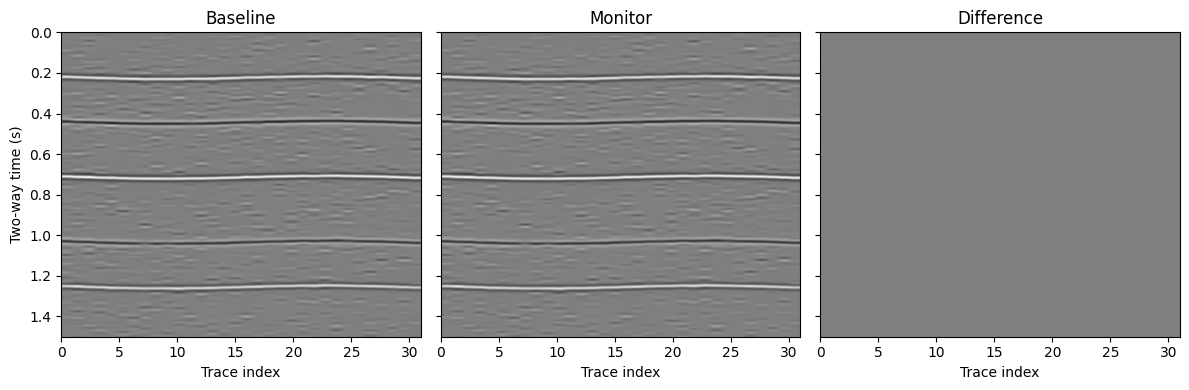

In [2]:
e0 = experiments['E0']
assert np.array_equal(e0.baseline, e0.monitor)
assert np.all(e0.shift_event_s == 0)
print('E0 exact identity verified')
fig, ax = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for a, d, title in zip(ax, [e0.baseline, e0.monitor, e0.monitor-e0.baseline], ['Baseline', 'Monitor', 'Difference']):
    vmax = np.max(np.abs(e0.baseline)) if title != 'Difference' else np.max(np.abs(e0.baseline))
    a.imshow(d, cmap='gray', aspect='auto', vmin=-vmax, vmax=vmax, extent=[0, config.nx-1, e0.time_s[-1], 0])
    a.set_title(title); a.set_xlabel('Trace index')
ax[0].set_ylabel('Two-way time (s)')
fig.tight_layout(); fig.savefig(OUTPUT / 'E0_identical.png', dpi=150); plt.show()

## E1 — Constant shifts: −8, −4, 0, +4, +8 ms

Inspect the event near 440 ms (a negative-amplitude reflector). At +4 ms it must appear **later** in monitor, and at −4 ms **earlier**. Constant integer-sample delays preserve amplitude exactly away from the interpolation boundaries.

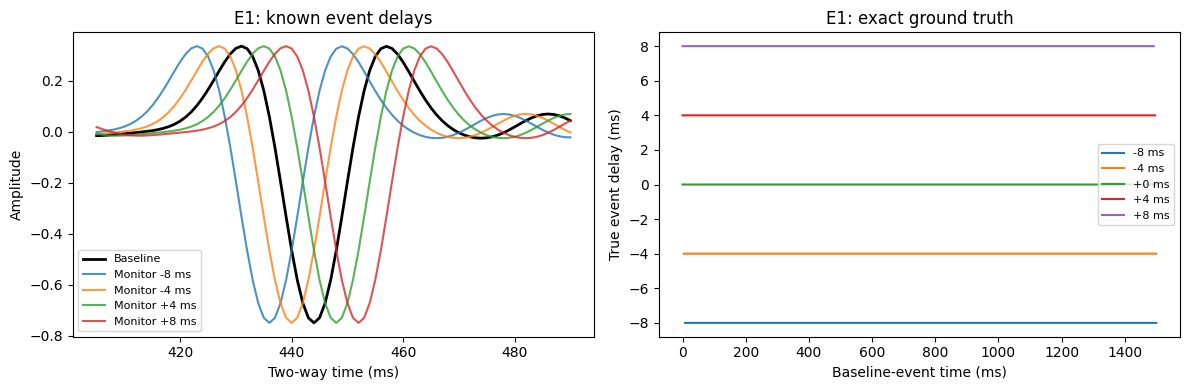

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
trace = config.nx // 2
sel = (e0.time_s >= 0.405) & (e0.time_s <= 0.49)
axes[0].plot(e0.time_s[sel]*1000, e0.baseline[sel, trace], 'k', label='Baseline', lw=2)
for v in (-8, -4, 4, 8):
    p = experiments[f'E1_{v:+d}ms']
    axes[0].plot(p.time_s[sel]*1000, p.monitor[sel, trace], label=f'Monitor {v:+d} ms', alpha=.8)
axes[0].set(xlabel='Two-way time (ms)', ylabel='Amplitude', title='E1: known event delays'); axes[0].legend(fontsize=8)
for v in (-8, -4, 0, 4, 8):
    p = experiments[f'E1_{v:+d}ms']
    axes[1].plot(p.time_s*1000, p.shift_event_s[:, trace]*1000, label=f'{v:+d} ms')
axes[1].set(xlabel='Baseline-event time (ms)', ylabel='True event delay (ms)', title='E1: exact ground truth'); axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUTPUT / 'E1_constant_shift.png', dpi=150); plt.show()

## E2 — Smoothly varying time shift

The defined resampling uses `F(t)=t-shift_monitor(t)`. The inverse `g(u)=F⁻¹(u)` maps baseline event time to monitor time; `shift_event(u)=g(u)-u`. The two shift curves are **not exactly identical** for variable shifts. Time strain is the derivative with respect to the specified coordinate.

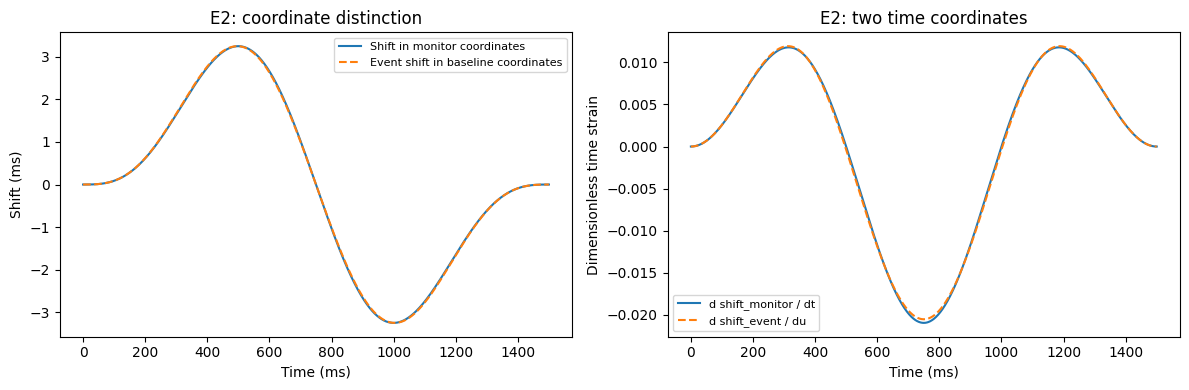

Min slope of F(t): 0.988219067036944
Max defined event shift (ms): 3.2475811451656567


In [4]:
e2 = experiments['E2']
t = e2.time_s
j = config.nx//2
f = t-e2.shift_monitor_s[:,j]
assert np.all(np.diff(f)>0), 'Non-monotone map'
valid = np.isfinite(e2.shift_event_s[:,j])
strain_monitor = np.gradient(e2.shift_monitor_s[:,j], config.dt)
strain_event = np.gradient(e2.shift_event_s[:,j], config.dt)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(t*1000, e2.shift_monitor_s[:,j]*1000, label='Shift in monitor coordinates')
axes[0].plot(t[valid]*1000, e2.shift_event_s[valid,j]*1000, '--', label='Event shift in baseline coordinates')
axes[0].set(xlabel='Time (ms)', ylabel='Shift (ms)', title='E2: coordinate distinction'); axes[0].legend(fontsize=8)
axes[1].plot(t*1000, strain_monitor, label='d shift_monitor / dt')
axes[1].plot(t[valid]*1000, strain_event[valid], '--', label='d shift_event / du')
axes[1].set(xlabel='Time (ms)', ylabel='Dimensionless time strain', title='E2: two time coordinates'); axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUTPUT / 'E2_shift_and_strain.png', dpi=150); plt.show()
print('Min slope of F(t):', np.diff(f).min()/config.dt)
print('Max defined event shift (ms):', np.nanmax(np.abs(e2.shift_event_s))*1000)

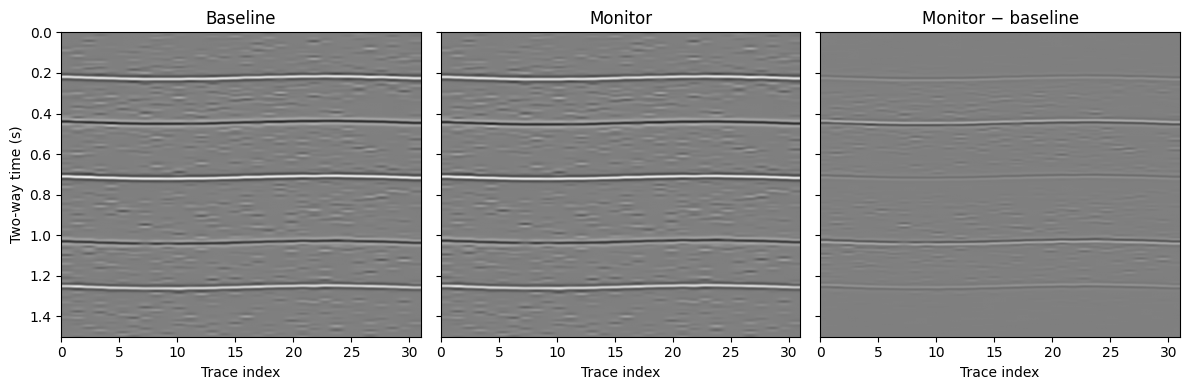

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
vmax = np.max(np.abs(e2.baseline))
for a, arr, title in zip(axes, [e2.baseline, e2.monitor, e2.monitor-e2.baseline], ['Baseline', 'Monitor', 'Monitor − baseline']):
    a.imshow(arr, cmap='gray', vmin=-vmax, vmax=vmax, aspect='auto', extent=[0, config.nx-1, t[-1], 0])
    a.set(title=title, xlabel='Trace index')
axes[0].set_ylabel('Two-way time (s)')
fig.tight_layout(); fig.savefig(OUTPUT / 'E2_sections.png', dpi=150); plt.show()

## Scientific QC and interpretation

1. In E0, the difference **must be exactly zero** (we have tested this).
2. In E1, positive delay must move the monitor event **downward** on the displayed time axis. Integer-sample shifts leave interior sample amplitudes unchanged; outside support, samples are explicitly `NaN`, not zeros.
3. In E2, `F(t)` must be strictly increasing. Inspect the difference section, shift and time-strain curves. There is no algorithmic estimated time shift at this stage: these are exact synthetic truths.
4. Before CC/DTW, decide which time coordinate each estimator returns and transform its output to baseline-event coordinates for RMSE.

**Next:** implement windowed CC as an independent estimator and benchmark on E0–E2.